# Phase 3 — Exploratory Data Analysis (EDA)
**Olist business question:** Where is revenue coming from, which customers are most valuable, and what is hurting customer satisfaction?

**Prerequisite:** Complete Phase 2 and export seven files into `data/processed/`:
`customers_cleaned.csv`, `orders_cleaned.csv`, `order_items_cleaned.csv`, `payments_cleaned.csv`, `reviews_cleaned.csv`, `products_cleaned.csv`, `sellers_cleaned.csv`.

This notebook analyzes the cleaned data. It does not delete or overwrite source records.

## Sprint 1 — Setup and load data

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_root / "data" / "processed"
figures_path = project_root / "reports" / "figures"
tables_path = project_root / "reports" / "tables"
figures_path.mkdir(parents=True, exist_ok=True)
tables_path.mkdir(parents=True, exist_ok=True)

files = {
    "customers": "customers_cleaned.csv",
    "orders": "orders_cleaned.csv",
    "order_items": "order_items_cleaned.csv",
    "payments": "payments_cleaned.csv",
    "reviews": "reviews_cleaned.csv",
    "products": "products_cleaned.csv",
    "sellers": "sellers_cleaned.csv"
}
missing = [f for f in files.values() if not (data_path / f).exists()]
if missing:
    raise FileNotFoundError("Finish Phase 2 first. Missing: " + ", ".join(missing))

dfs = {name: pd.read_csv(data_path / file) for name, file in files.items()}
for name, df in dfs.items():
    print(f"{name}: {df.shape[0]:,} rows x {df.shape[1]} columns")

customers, orders = dfs["customers"], dfs["orders"]
order_items, payments = dfs["order_items"], dfs["payments"]
reviews, products, sellers = dfs["reviews"], dfs["products"], dfs["sellers"]

customers: 99,441 rows x 5 columns
orders: 99,441 rows x 9 columns
order_items: 112,650 rows x 7 columns
payments: 103,886 rows x 5 columns
reviews: 99,224 rows x 7 columns
products: 32,951 rows x 12 columns
sellers: 3,095 rows x 4 columns


In [6]:
date_cols = {
    "orders": ["order_purchase_timestamp", "order_approved_at",
               "order_delivered_carrier_date", "order_delivered_customer_date",
               "order_estimated_delivery_date"],
    "order_items": ["shipping_limit_date"],
    "reviews": ["review_creation_date", "review_answer_timestamp"]
}
for table, cols in date_cols.items():
    for col in cols:
        if col in dfs[table].columns:
            dfs[table][col] = pd.to_datetime(dfs[table][col], errors="coerce")

customers, orders = dfs["customers"], dfs["orders"]
order_items, payments = dfs["order_items"], dfs["payments"]
reviews, products, sellers = dfs["reviews"], dfs["orders"], dfs["sellers"]
# Correct products/reviews references after loading
reviews, products = dfs["reviews"], dfs["products"]

orders[["order_id", "order_purchase_timestamp", "order_status"]].head()

,order_id,order_purchase_timestamp,order_status
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,delivered
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,delivered
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,delivered
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,delivered
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,delivered


## Sprint 2 — Overall business KPIs

In [7]:
order_revenue = order_items.groupby("order_id", as_index=False)["price"].sum()
kpis = pd.DataFrame({
    "Metric": ["Orders", "Unique customers", "Order items", "Sellers", "Products",
               "Item revenue", "Freight value", "Average review score"],
    "Value": [orders.order_id.nunique(), customers.customer_unique_id.nunique(),
              len(order_items), sellers.seller_id.nunique(), products.product_id.nunique(),
              order_items.price.sum(), order_items.freight_value.sum(),
              reviews.review_score.mean()]
})
kpis

,Metric,Value
0,Orders,"99,441.00"
1,Unique customers,"96,096.00"
2,Order items,"112,650.00"
3,Sellers,"3,095.00"
4,Products,"32,951.00"
5,Item revenue,"13,591,643.70"
6,Freight value,"2,251,909.54"
7,Average review score,4.09


,status,orders,percentage
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


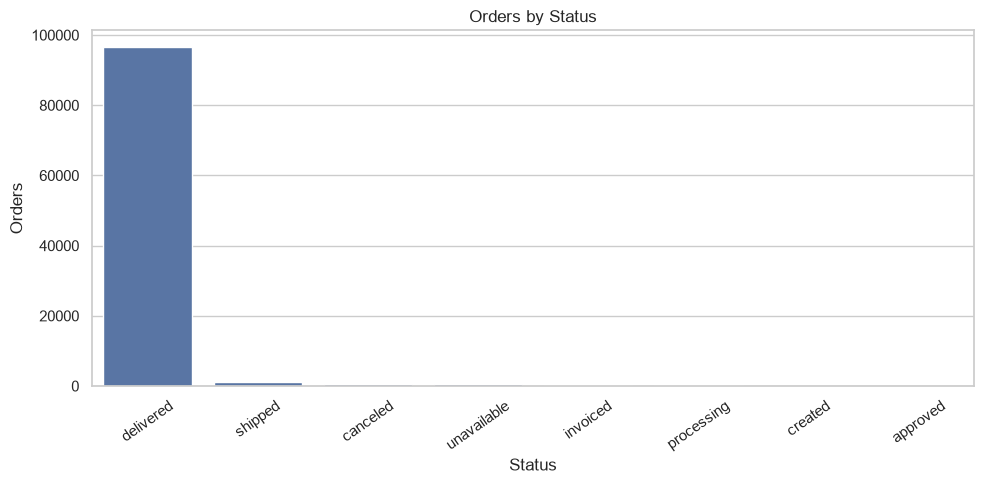

In [8]:
status = orders.order_status.value_counts().rename_axis("status").reset_index(name="orders")
status["percentage"] = status.orders / status.orders.sum() * 100
display(status)
plt.figure(figsize=(10,5))
sns.barplot(data=status, x="status", y="orders")
plt.title("Orders by Status"); plt.xlabel("Status"); plt.ylabel("Orders")
plt.xticks(rotation=35); plt.tight_layout()
plt.savefig(figures_path / "orders_by_status.png", dpi=150); plt.show()

**Think:** Which statuses dominate? What share are canceled or unavailable? Why should those orders be separated from delivered orders?

## Sprint 3 — Monthly orders and revenue

In [9]:
orders["purchase_month"] = orders.order_purchase_timestamp.dt.to_period("M").dt.to_timestamp()
monthly_orders = orders.groupby("purchase_month").order_id.nunique().rename("orders")
orders_rev = orders.merge(order_revenue, on="order_id", how="left")
monthly_revenue = orders_rev.groupby("purchase_month").price.sum().rename("item_revenue")
monthly = pd.concat([monthly_orders, monthly_revenue], axis=1).reset_index()
monthly.head()

,purchase_month,orders,item_revenue
0,2016-09-01,4,267.36
1,2016-10-01,324,"49,507.66"
2,2016-12-01,1,10.90
3,2017-01-01,800,"120,312.87"
4,2017-02-01,1780,"247,303.02"


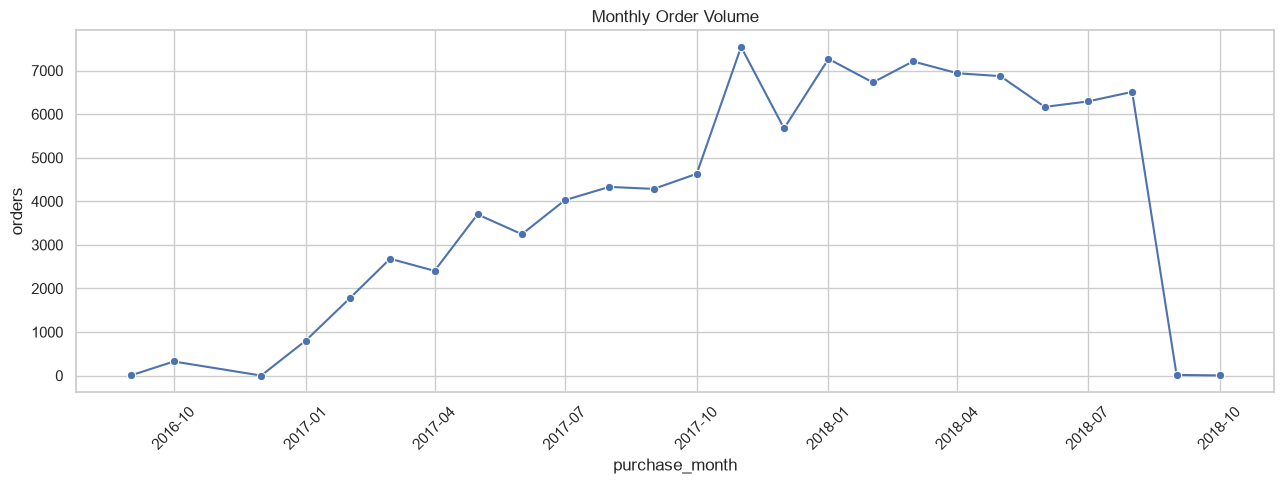

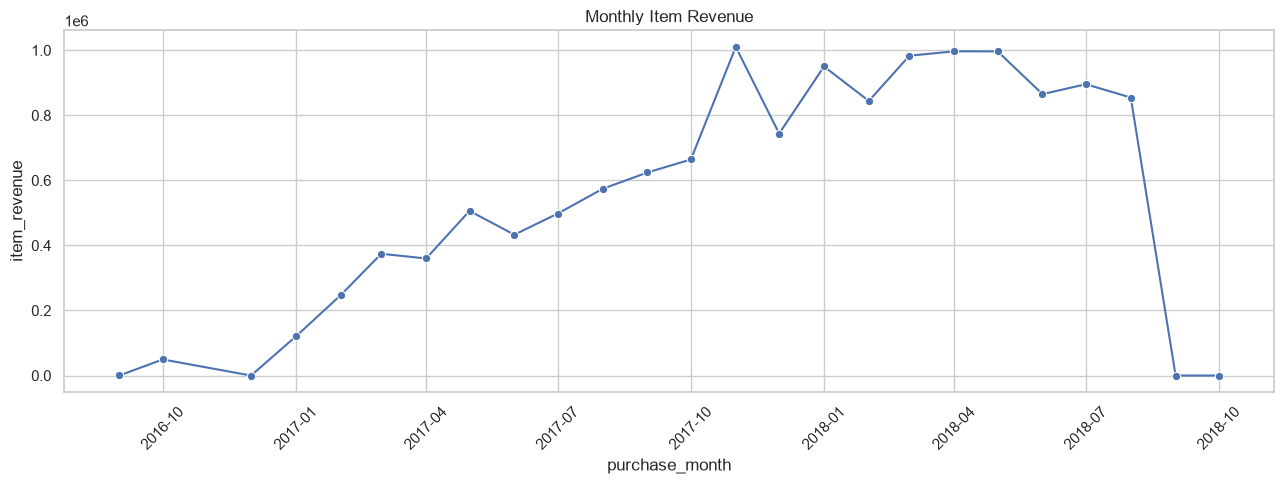

In [10]:
plt.figure(figsize=(13,5))
sns.lineplot(data=monthly, x="purchase_month", y="orders", marker="o")
plt.title("Monthly Order Volume"); plt.xticks(rotation=45); plt.tight_layout()
plt.savefig(figures_path / "monthly_orders.png", dpi=150); plt.show()

plt.figure(figsize=(13,5))
sns.lineplot(data=monthly, x="purchase_month", y="item_revenue", marker="o")
plt.title("Monthly Item Revenue"); plt.xticks(rotation=45); plt.tight_layout()
plt.savefig(figures_path / "monthly_revenue.png", dpi=150); plt.show()

**Think:** Which months lead in order volume and revenue? Do the two trends move together?

## Sprint 4 — Product category performance

In [11]:
item_product = order_items.merge(
    products[["product_id", "product_category_name"]], on="product_id", how="left"
)
category = (item_product.groupby("product_category_name", dropna=False)
    .agg(item_revenue=("price","sum"), items_sold=("order_item_id","count"),
         avg_item_price=("price","mean"), freight=("freight_value","sum"))
    .reset_index().sort_values("item_revenue", ascending=False))
category.head(15)

,product_category_name,item_revenue,items_sold,avg_item_price,freight
11,beleza_saude,"1,258,681.34",9670,130.16,"182,566.73"
66,relogios_presentes,"1,205,005.68",5991,201.14,"100,535.93"
13,cama_mesa_banho,"1,036,988.68",11115,93.30,"204,693.04"
32,esporte_lazer,"988,048.97",8641,114.34,"168,607.51"
44,informatica_acessorios,"911,954.32",7827,116.51,"147,318.08"
54,moveis_decoracao,"729,762.49",8334,87.56,"172,749.30"
26,cool_stuff,"635,290.85",3796,167.36,"84,039.10"
72,utilidades_domesticas,"632,248.66",6964,90.79,"146,149.11"
8,automotivo,"592,720.11",4235,139.96,"92,664.21"
40,ferramentas_jardim,"485,256.46",4347,111.63,"98,962.75"


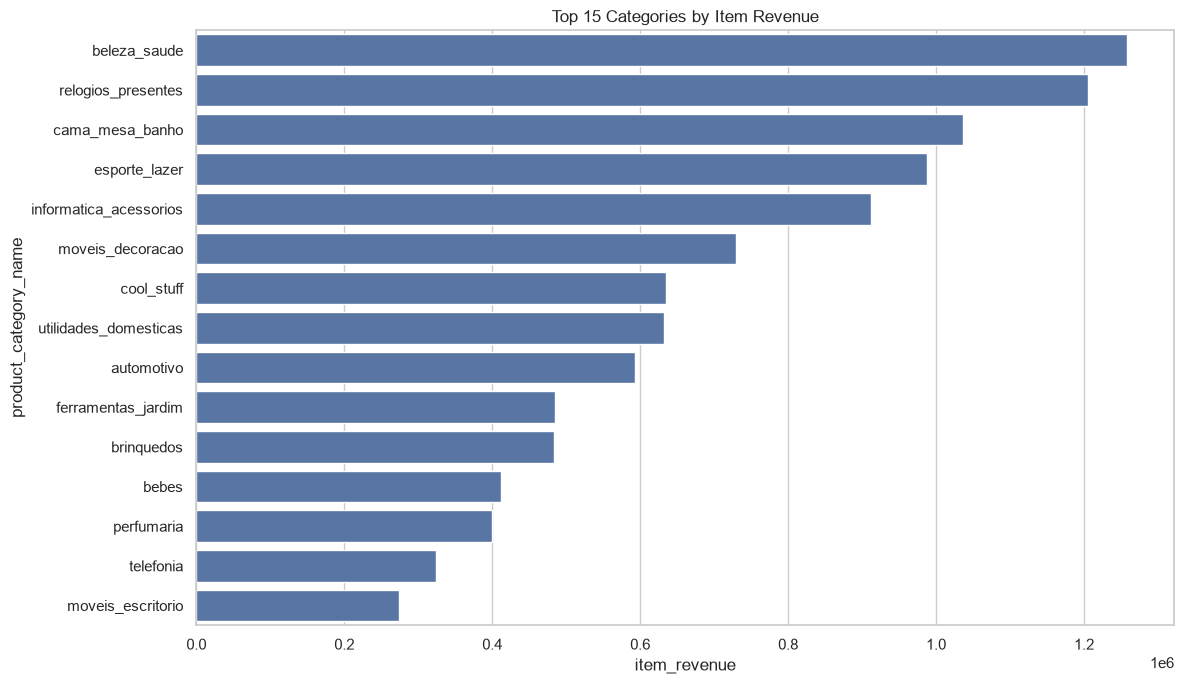

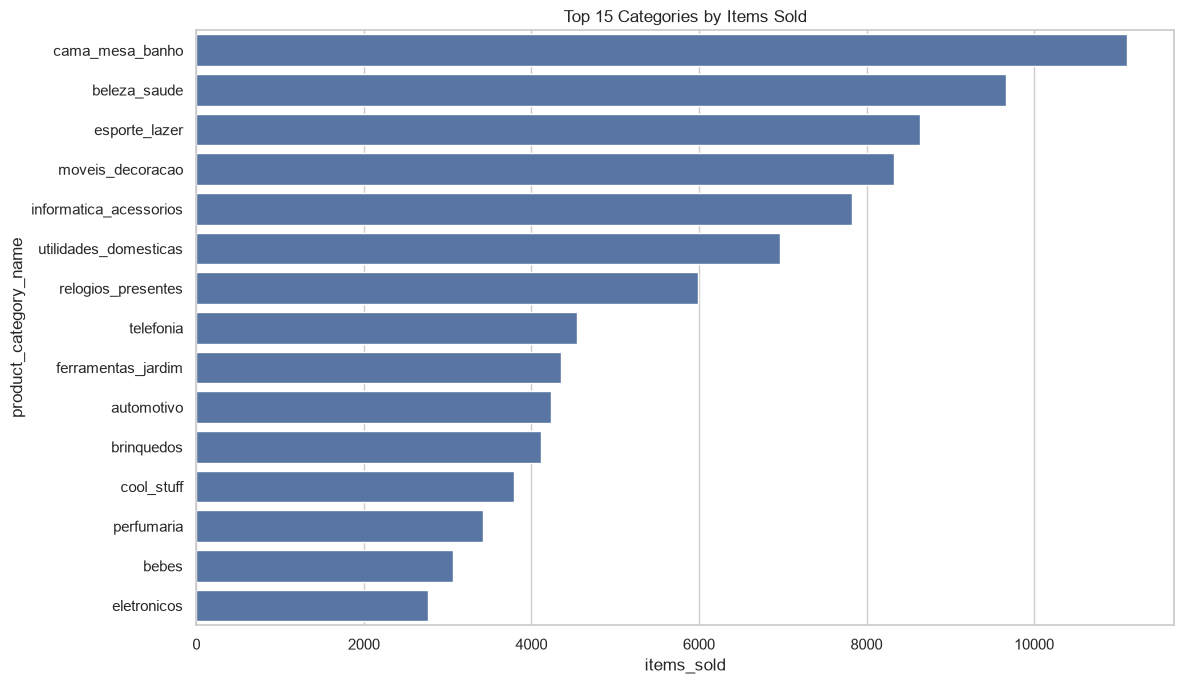

In [12]:
top = category.head(15)
plt.figure(figsize=(12,7))
sns.barplot(data=top, y="product_category_name", x="item_revenue")
plt.title("Top 15 Categories by Item Revenue"); plt.tight_layout()
plt.savefig(figures_path / "top_categories_revenue.png", dpi=150); plt.show()

top_volume = category.sort_values("items_sold", ascending=False).head(15)
plt.figure(figsize=(12,7))
sns.barplot(data=top_volume, y="product_category_name", x="items_sold")
plt.title("Top 15 Categories by Items Sold"); plt.tight_layout()
plt.savefig(figures_path / "top_categories_volume.png", dpi=150); plt.show()

**Think:** Are the categories with the highest revenue also the ones with the highest item volume?

## Sprint 5 — Geographic performance

In [13]:
orders_cust = orders.merge(
    customers[["customer_id", "customer_state", "customer_unique_id"]],
    on="customer_id", how="left"
)
state_orders = orders_cust.groupby("customer_state").agg(
    orders=("order_id","nunique"), customers=("customer_unique_id","nunique")
).reset_index()
state_rev = orders_rev.merge(
    customers[["customer_id","customer_state"]], on="customer_id", how="left"
).groupby("customer_state").price.sum().rename("item_revenue").reset_index()
state = state_orders.merge(state_rev, on="customer_state", how="left")
state.sort_values("item_revenue", ascending=False).head(15)

,customer_state,orders,customers,item_revenue
25,SP,41746,40302,"5,202,955.05"
18,RJ,12852,12384,"1,824,092.67"
10,MG,11635,11259,"1,585,308.03"
22,RS,5466,5277,"750,304.02"
17,PR,5045,4882,"683,083.76"
23,SC,3637,3534,"520,553.34"
4,BA,3380,3277,"511,349.99"
6,DF,2140,2075,"302,603.94"
8,GO,2020,1952,"294,591.95"
7,ES,2033,1964,"275,037.31"


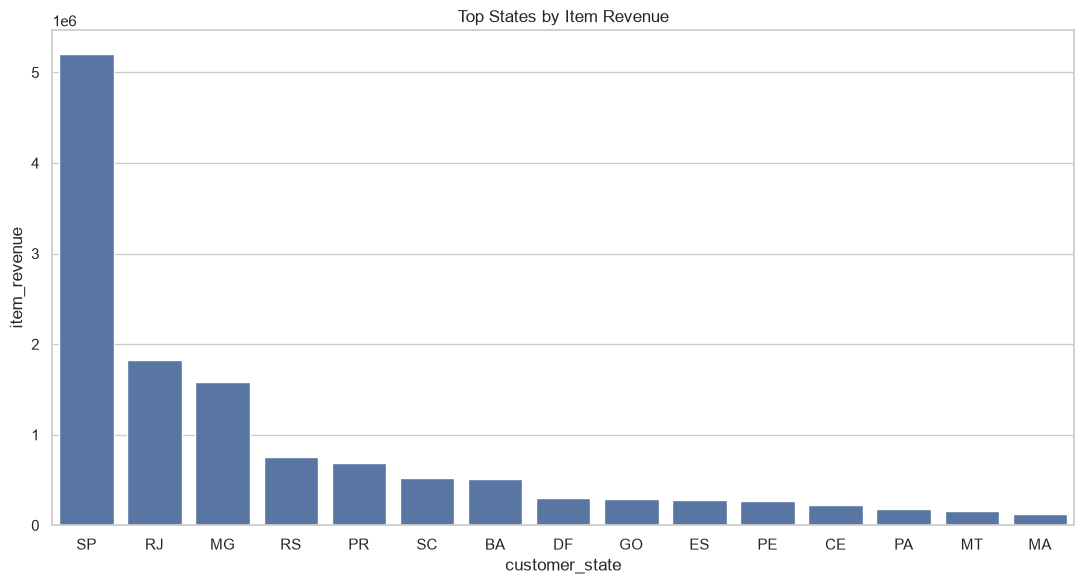

In [14]:
top_states = state.sort_values("item_revenue", ascending=False).head(15)
plt.figure(figsize=(11,6))
sns.barplot(data=top_states, x="customer_state", y="item_revenue")
plt.title("Top States by Item Revenue"); plt.tight_layout()
plt.savefig(figures_path / "revenue_by_state.png", dpi=150); plt.show()

**Think:** Which states contribute the most revenue? Do they also have the most orders?

## Sprint 6 — Customer value and repeat purchases

In [15]:
customer_orders = orders.merge(
    customers[["customer_id","customer_unique_id"]], on="customer_id", how="left"
).merge(order_revenue, on="order_id", how="left")
customer_orders["price"] = customer_orders.price.fillna(0)

customer_value = customer_orders.groupby("customer_unique_id").agg(
    orders=("order_id","nunique"), total_item_revenue=("price","sum"),
    first_purchase=("order_purchase_timestamp","min"),
    last_purchase=("order_purchase_timestamp","max")
).reset_index()
customer_value["segment"] = np.where(customer_value.orders > 1, "Repeat", "One-time")
customer_value.sort_values("total_item_revenue", ascending=False).head(15)

,customer_unique_id,orders,total_item_revenue,first_purchase,last_purchase,segment
3826,0a0a92112bd4c708ca5fde585afaa872,1,"13,440.00",2017-09-29 15:24:52,2017-09-29 15:24:52,One-time
81962,da122df9eeddfedc1dc1f5349a1a690c,2,"7,388.00",2017-04-01 15:58:40,2017-04-01 15:58:41,Repeat
44447,763c8b1c9c68a0229c42c9fc6f662b93,1,"7,160.00",2018-07-15 14:49:44,2018-07-15 14:49:44,One-time
82808,dc4802a71eae9be1dd28f5d788ceb526,1,"6,735.00",2017-02-12 20:37:36,2017-02-12 20:37:36,One-time
26205,459bef486812aa25204be022145caa62,1,"6,729.00",2018-07-25 18:10:17,2018-07-25 18:10:17,One-time
95806,ff4159b92c40ebe40454e3e6a7c35ed6,1,"6,499.00",2017-05-24 18:14:34,2017-05-24 18:14:34,One-time
24121,4007669dec559734d6f53e029e360987,1,"5,934.60",2017-11-24 11:03:35,2017-11-24 11:03:35,One-time
89688,eebb5dda148d3893cdaf5b5ca3040ccb,1,"4,690.00",2017-04-18 18:50:13,2017-04-18 18:50:13,One-time
35070,5d0a2980b292d049061542014e8960bf,1,"4,599.90",2018-07-12 12:08:36,2018-07-12 12:08:36,One-time
27441,48e1ac109decbb87765a3eade6854098,1,"4,590.00",2018-06-22 12:23:19,2018-06-22 12:23:19,One-time


In [16]:
segments = customer_value.groupby("segment").agg(
    customers=("customer_unique_id","nunique"),
    total_revenue=("total_item_revenue","sum"),
    avg_revenue_per_customer=("total_item_revenue","mean"),
    avg_orders=("orders","mean")
).reset_index()
segments["customer_pct"] = segments.customers / segments.customers.sum() * 100
segments

,segment,customers,total_revenue,avg_revenue_per_customer,avg_orders,customer_pct
0,One-time,93099,"12,812,821.73",137.63,1.00,96.88
1,Repeat,2997,"778,821.97",259.87,2.12,3.12


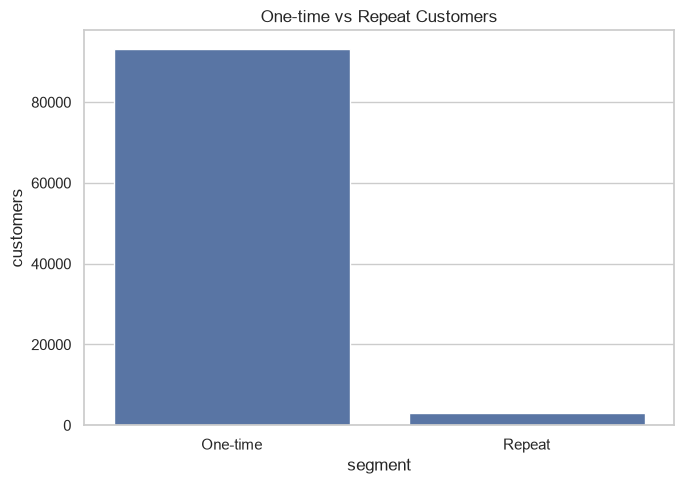

In [17]:
plt.figure(figsize=(7,5))
sns.barplot(data=segments, x="segment", y="customers")
plt.title("One-time vs Repeat Customers"); plt.tight_layout()
plt.savefig(figures_path / "customer_segments.png", dpi=150); plt.show()

**Think:** What share of customers are repeat buyers? How much revenue comes from each segment? This is historical customer value, not predicted lifetime value.

## Sprint 7 — Payment behavior

In [18]:
payment_summary = payments.groupby("payment_type").agg(
    payment_records=("payment_type","size"),
    total_payment_value=("payment_value","sum"),
    avg_payment_value=("payment_value","mean"),
    avg_installments=("payment_installments","mean")
).reset_index().sort_values("total_payment_value", ascending=False)
payment_summary

,payment_type,payment_records,total_payment_value,avg_payment_value,avg_installments
1,credit_card,76795,"12,542,084.19",163.32,3.51
0,boleto,19784,"2,869,361.27",145.03,1.00
4,voucher,5775,"379,436.87",65.70,1.00
2,debit_card,1529,"217,989.79",142.57,1.00
3,not_defined,3,0.00,0.00,1.00


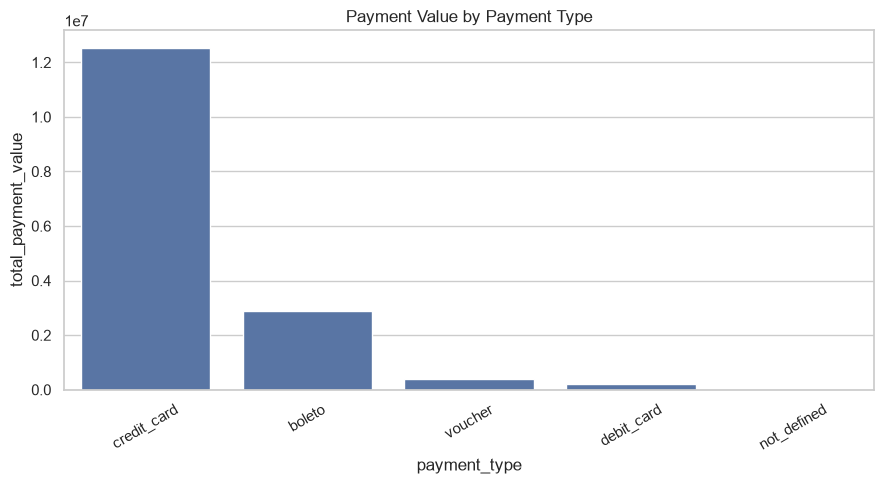

,payment_type,count,mean,median,max
0,boleto,19784,1.00,1.00,1
1,credit_card,76793,3.51,3.00,24
2,debit_card,1529,1.00,1.00,1
3,not_defined,3,1.00,1.00,1
4,voucher,5775,1.00,1.00,1


In [19]:
plt.figure(figsize=(9,5))
sns.barplot(data=payment_summary, x="payment_type", y="total_payment_value")
plt.title("Payment Value by Payment Type")
plt.xticks(rotation=30); plt.tight_layout()
plt.savefig(figures_path / "payment_value_by_type.png", dpi=150); plt.show()

payments.loc[payments.payment_installments > 0].groupby("payment_type").payment_installments.agg(
    ["count","mean","median","max"]
).reset_index()

**Think:** Which payment type contributes the most payment value? Why might payment value differ from item revenue?

## Sprint 8 — Delivery performance

In [20]:
delivery = orders.loc[
    (orders.order_status == "delivered") &
    orders.order_purchase_timestamp.notna() &
    orders.order_delivered_customer_date.notna()
].copy()
delivery["delivery_days"] = (
    delivery.order_delivered_customer_date - delivery.order_purchase_timestamp
).dt.total_seconds() / 86400
delivery["delivery_vs_estimate_days"] = (
    delivery.order_delivered_customer_date - delivery.order_estimated_delivery_date
).dt.total_seconds() / 86400
delivery[["delivery_days","delivery_vs_estimate_days"]].describe()

,delivery_days,delivery_vs_estimate_days
count,"96,470.00","96,470.00"
mean,12.56,-11.18
std,9.55,10.18
min,0.53,-146.02
25%,6.77,-16.24
50%,10.22,-11.95
75%,15.72,-6.39
max,209.63,188.98


In [21]:
negative_delivery = delivery.loc[delivery.delivery_days < 0]
print("Negative delivery durations:", len(negative_delivery))
display(negative_delivery[["order_id","order_purchase_timestamp",
                           "order_delivered_customer_date","delivery_days"]].head())

valid_delivery = delivery.loc[delivery.delivery_days >= 0].copy()
valid_delivery["delivery_result"] = np.where(
    valid_delivery.delivery_vs_estimate_days <= 0, "On or before estimate", "Late"
)
delivery_result = valid_delivery.delivery_result.value_counts().rename_axis(
    "delivery_result").reset_index(name="orders")
delivery_result["percentage"] = delivery_result.orders / delivery_result.orders.sum() * 100
delivery_result

Negative delivery durations: 0


,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_days


,delivery_result,orders,percentage
0,On or before estimate,88644,91.89
1,Late,7826,8.11


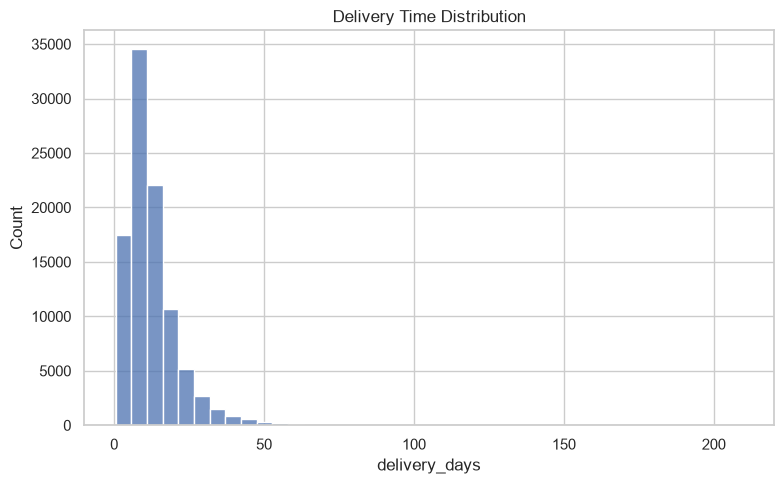

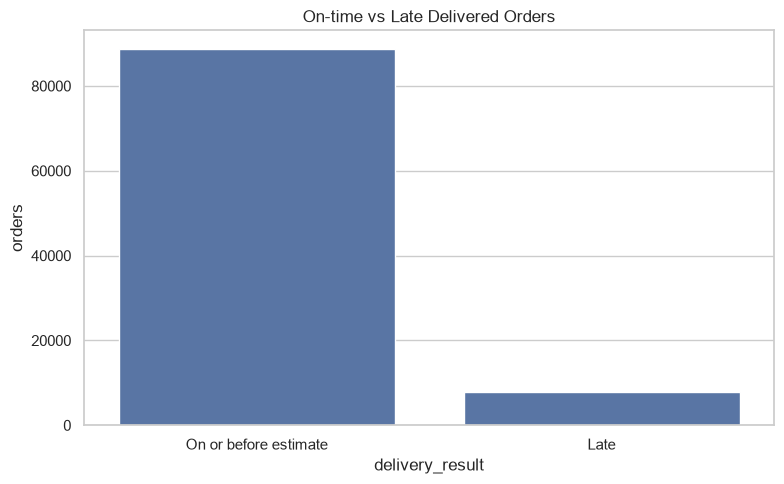

In [22]:
plt.figure(figsize=(8,5))
sns.histplot(data=valid_delivery, x="delivery_days", bins=40)
plt.title("Delivery Time Distribution"); plt.tight_layout()
plt.savefig(figures_path / "delivery_time_distribution.png", dpi=150); plt.show()

plt.figure(figsize=(8,5))
sns.barplot(data=delivery_result, x="delivery_result", y="orders")
plt.title("On-time vs Late Delivered Orders"); plt.tight_layout()
plt.savefig(figures_path / "delivery_on_time_vs_late.png", dpi=150); plt.show()

**Think:** What are mean and median delivery days? What percentage arrived late? Why analyze only delivered orders with valid timestamps?

In [32]:
valid_delivery = orders[
    (orders['order_status'] == 'delivered') &
    orders['order_delivered_customer_date'].notna() &
    orders['order_estimated_delivery_date'].notna()
].copy()

valid_delivery['delivery_vs_estimate_days'] = (
    valid_delivery['order_delivered_customer_date'] -
    valid_delivery['order_estimated_delivery_date']
).dt.total_seconds() / 86400

valid_delivery['late_delivery'] = (
    valid_delivery['delivery_vs_estimate_days'] > 0
)

print("Valid delivered orders:", len(valid_delivery))
print("Late deliveries:", valid_delivery['late_delivery'].sum())
print(
    "Late delivery percentage:",
    round(valid_delivery['late_delivery'].mean() * 100, 2), "%"
)

Valid delivered orders: 96470
Late deliveries: 7826
Late delivery percentage: 8.11 %


In [33]:
print("Reviews with valid order IDs:", len(reviews[
    reviews['order_id'].isin(orders['order_id'])
]))

print("Reviews with valid delivery dates:", len(
    reviews.merge(
        valid_delivery[['order_id']],
        on='order_id',
        how='inner'
    )
))

print("Unique review order IDs:", reviews['order_id'].nunique())

Reviews with valid order IDs: 99224
Reviews with valid delivery dates: 96353
Unique review order IDs: 98673


In [34]:
print("Review records:", len(reviews))
print("Unique reviewed orders:", reviews['order_id'].nunique())
print(
    "Duplicate review order IDs:",
    reviews['order_id'].duplicated().sum()
)

print(
    "Review records with duplicate review IDs:",
    reviews['review_id'].duplicated().sum()
)

Review records: 99224
Unique reviewed orders: 98673
Duplicate review order IDs: 551
Review records with duplicate review IDs: 814


In [35]:
valid_order_ids = set(valid_delivery['order_id'])
reviewed_order_ids = set(reviews['order_id'])

print("Valid delivered orders:", len(valid_order_ids))

print(
    "Delivered orders with reviews:",
    len(valid_order_ids & reviewed_order_ids)
)

print(
    "Delivered orders without reviews:",
    len(valid_order_ids - reviewed_order_ids)
)

matched_reviews = reviews[
    reviews['order_id'].isin(valid_order_ids)
]

print("Matched review records:", len(matched_reviews))
print("Unique matched review orders:", matched_reviews['order_id'].nunique())

Valid delivered orders: 96470
Delivered orders with reviews: 95824
Delivered orders without reviews: 646
Matched review records: 96353
Unique matched review orders: 95824


In [36]:
credit = payments[
    payments['payment_type'] == 'credit_card'
]

print("All credit card records:", len(credit))
print("Zero installments:", (credit['payment_installments'] == 0).sum())
print("Negative installments:", (credit['payment_installments'] < 0).sum())
print("Missing installments:", credit['payment_installments'].isna().sum())

All credit card records: 76795
Zero installments: 2
Negative installments: 0
Missing installments: 0


In [40]:
extreme_delivery_check = orders.loc[
    (orders['order_status'] == 'delivered') &
    orders['order_purchase_timestamp'].notna() &
    orders['order_delivered_customer_date'].notna()
].copy()

extreme_delivery_check['delivery_days'] = (
    extreme_delivery_check['order_delivered_customer_date'] -
    extreme_delivery_check['order_purchase_timestamp']
).dt.total_seconds() / 86400

extreme_delivery_check['delivery_vs_estimate_days'] = (
    extreme_delivery_check['order_delivered_customer_date'] -
    extreme_delivery_check['order_estimated_delivery_date']
).dt.total_seconds() / 86400

extreme_deliveries = extreme_delivery_check[
    extreme_delivery_check['delivery_days'] > 60
].sort_values('delivery_days', ascending=False)

print("Orders taking more than 60 days:", len(extreme_deliveries))

display(
    extreme_deliveries[
        [
            'order_id',
            'order_purchase_timestamp',
            'order_delivered_customer_date',
            'order_estimated_delivery_date',
            'delivery_days',
            'delivery_vs_estimate_days'
        ]
    ].head(10)
)

Orders taking more than 60 days: 306


,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delivery_vs_estimate_days
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22,209.63,181.61
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,208.35,188.98
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-09-19 15:12:50,2017-04-07,195.63,165.63
70307,2fb597c2f772eca01b1f5c561bf6cc7b,2017-03-08 18:09:02,2017-09-19 14:33:17,2017-04-17,194.85,155.61
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,194.63,166.58
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-09-19 14:38:21,2017-04-11,194.05,161.61
11399,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19,191.46,175.87
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05,189.86,167.71
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:27,2017-09-19 14:38:18,2017-04-13,188.13,159.61
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:17,2017-09-19 17:14:25,2017-04-10,187.74,162.72


In [41]:
print("Orders over 30 days:",
      (extreme_delivery_check['delivery_days'] > 30).sum())

print("Orders over 60 days:",
      (extreme_delivery_check['delivery_days'] > 60).sum())

print("Orders over 90 days:",
      (extreme_delivery_check['delivery_days'] > 90).sum())

Orders over 30 days: 4550
Orders over 60 days: 306
Orders over 90 days: 77


## Sprint 9 — Customer satisfaction and reviews

In [23]:
review_summary = reviews.review_score.value_counts().sort_index().rename_axis(
    "review_score").reset_index(name="reviews")
review_summary["percentage"] = review_summary.reviews / review_summary.reviews.sum() * 100
review_summary

,review_score,reviews,percentage
0,1,11424,11.51
1,2,3151,3.18
2,3,8179,8.24
3,4,19142,19.29
4,5,57328,57.78


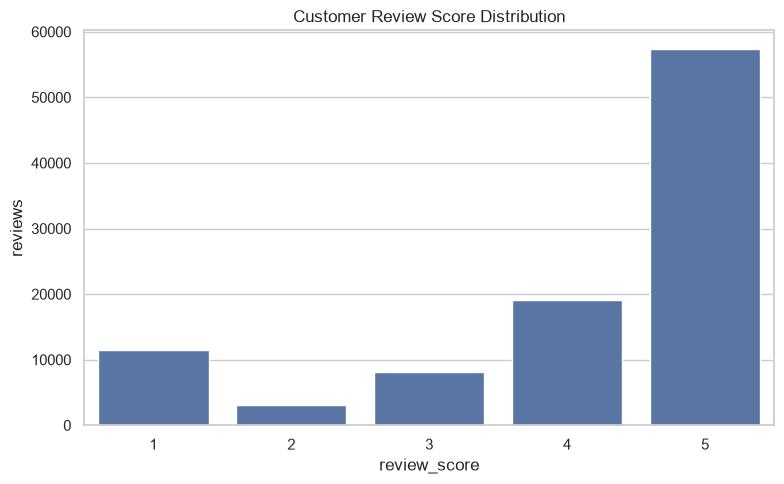

In [24]:
plt.figure(figsize=(8,5))
sns.barplot(data=review_summary, x="review_score", y="reviews")
plt.title("Customer Review Score Distribution"); plt.tight_layout()
plt.savefig(figures_path / "review_score_distribution.png", dpi=150); plt.show()

In [25]:
delivery_reviews = valid_delivery.merge(
    reviews[["order_id","review_score"]], on="order_id", how="inner"
)
display(delivery_reviews.groupby("review_score").delivery_days.agg(
    ["count","mean","median"]).reset_index())

delivery_reviews["delivery_result"] = np.where(
    delivery_reviews.delivery_vs_estimate_days <= 0,
    "On or before estimate", "Late"
)
delivery_review_comparison = delivery_reviews.groupby("delivery_result").review_score.agg(
    ["count","mean","median"]).reset_index()
delivery_review_comparison

,review_score,count,mean,median
0,1,9405,21.31,16.78
1,2,2941,16.66,13.25
2,3,7961,14.26,12.05
3,4,18987,12.31,10.79
4,5,57059,10.69,9.24


,delivery_result,count,mean,median
0,Late,7700,2.57,2.00
1,On or before estimate,88653,4.29,5.00


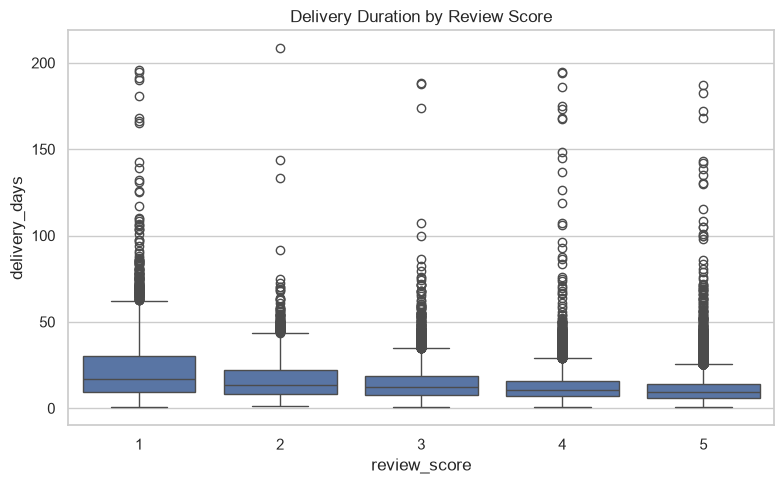

In [26]:
plt.figure(figsize=(8,5))
sns.boxplot(data=delivery_reviews, x="review_score", y="delivery_days")
plt.title("Delivery Duration by Review Score"); plt.tight_layout()
plt.savefig(figures_path / "delivery_days_by_review_score.png", dpi=150); plt.show()

**Think:** What percentage of reviews are scores 1–2? Do late deliveries appear associated with lower scores? Association does not prove causation.

## Sprint 10 — Save analysis tables and create findings summary

In [27]:
low_review_pct = reviews.review_score.isin([1,2]).mean() * 100
repeat_pct = (customer_value.orders > 1).mean() * 100
late_pct = (valid_delivery.delivery_vs_estimate_days > 0).mean() * 100

findings = pd.DataFrame({
    "Metric": ["Total orders", "Item revenue", "Average review score",
               "Low reviews (1-2) %", "Repeat customers %",
               "Late delivered orders %", "Average delivery days", "Median delivery days"],
    "Value": [orders.order_id.nunique(), order_items.price.sum(),
              reviews.review_score.mean(), low_review_pct, repeat_pct, late_pct,
              valid_delivery.delivery_days.mean(), valid_delivery.delivery_days.median()]
})
findings

,Metric,Value
0,Total orders,"99,441.00"
1,Item revenue,"13,591,643.70"
2,Average review score,4.09
3,Low reviews (1-2) %,14.69
4,Repeat customers %,3.12
5,Late delivered orders %,8.11
6,Average delivery days,12.56
7,Median delivery days,10.22


In [28]:
outputs = {
    "monthly_performance": monthly,
    "category_performance": category,
    "state_performance": state,
    "customer_value": customer_value,
    "customer_segments": segments,
    "payment_summary": payment_summary,
    "delivery_result": delivery_result,
    "review_summary": review_summary,
    "delivery_review_comparison": delivery_review_comparison,
    "findings_summary": findings
}
for name, frame in outputs.items():
    frame.to_csv(tables_path / f"{name}.csv", index=False)

print(f"Saved {len(outputs)} analysis tables to {tables_path}")
print(f"Charts saved to {figures_path}")

Saved 10 analysis tables to d:\Projects\olist-ecommerce-analysis\reports\tables
Charts saved to d:\Projects\olist-ecommerce-analysis\reports\figures


In [30]:
print("Orders columns:")
print(orders.columns.tolist())

print("\nDate-related columns:")
print([
    col for col in orders.columns
    if "date" in col.lower() or "timestamp" in col.lower()
])

Orders columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'flag_delivered_missing_customer_date', 'purchase_month']

Date-related columns:
['order_purchase_timestamp', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'flag_delivered_missing_customer_date']


In [31]:
print("Total reviews:", len(reviews))

print(
    "Reviews with valid order IDs:",
    reviews['order_id'].isin(orders['order_id']).sum()
)

print(
    "Orders with valid delivery dates:",
    orders['order_delivered_customer_date'].notna().sum()
)

print("Total payment records:", len(payments))

print(
    "Credit card payment records:",
    (payments['payment_type'] == 'credit_card').sum()
)

print(
    "Delivered orders:",
    (orders['order_status'] == 'delivered').sum()
)

print(
    "Delivered orders missing customer delivery date:",
    orders['flag_delivered_missing_customer_date'].sum()
)

Total reviews: 99224
Reviews with valid order IDs: 99224
Orders with valid delivery dates: 96476
Total payment records: 103886
Credit card payment records: 76795
Delivered orders: 96478
Delivered orders missing customer delivery date: 8
